# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [3]:
%pip -q install transformers torch matplotlib

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [4]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

C:\Users\lolwa\.conda\envs\nlp_lab9\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 269.57it/s]


Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [5]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [6]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [7]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

C:\Users\lolwa\.conda\envs\nlp_lab9\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\lolwa\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\lolwa\.conda\envs\nlp_lab9\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingfac

Number of Transformer layers: 12
Attention heads per layer: 12
Total attention heads: 144

Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Attention Matrix Shape: (11, 11)
Attention Weights:
 [[7.31758058e-01 7.91316852e-03 1.05913263e-02 5.55381039e-03
  1.65318456e-02 6.86041126e-03 1.00849932e-02 1.15875155e-02
  5.52019197e-03 3.86129729e-02 1.54985771e-01]
 [8.88825893e-01 4.70163953e-03 3.43816318e-02 1.78396498e-04
  2.73774099e-03 5.05419634e-03 9.01850814e-04 7.31915468e-04
  4.01142082e-04 5.11061167e-03 5.69749475e-02]
 [1.42731592e-01 5.68919182e-01 5.40587353e-03 3.53403501e-02
  4.11561839e-02 6.78862259e-02 8.96019340e-02 3.27414105e-04
  5.32992836e-03 8.96704383e-03 3.43342572e-02]
 [3.39528441e-01 7.31640607e-02 1.52498542e-03 1.61055432e-04
  2.01604322e-01 8.11239406e-02 6.35697022e-02 2.57090293e-02
  1.63918862e-03 2.84937546e-02 1.83481619e-01]
 [1.42912030e-01 6.96768984e-02 7.12884367e-02 6.394314

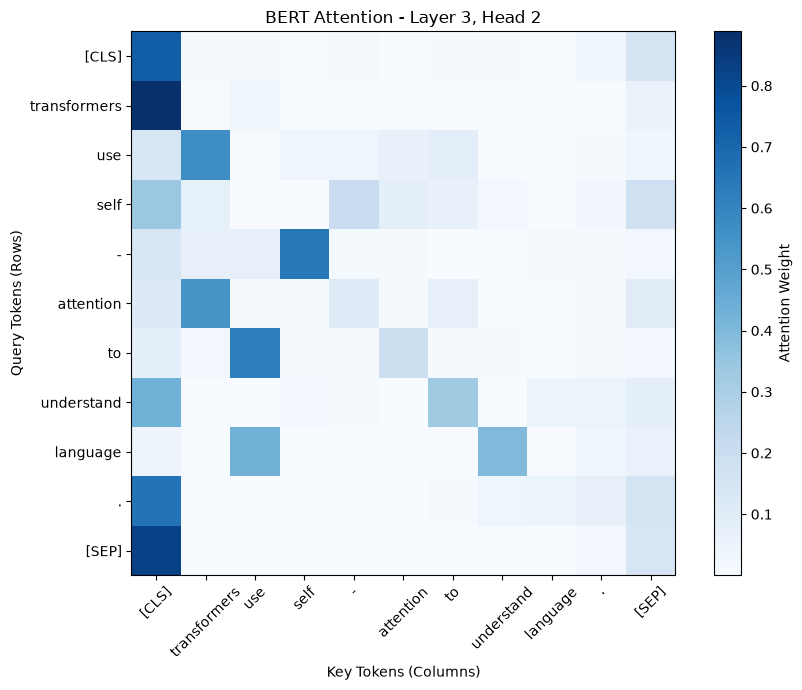

In [8]:
from transformers import AutoTokenizer, AutoModel
import torch
import matplotlib.pyplot as plt

# Load pretrained BERT model
model_name = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(model_name)
bert_model = AutoModel.from_pretrained(
    model_name,
    attn_implementation="eager"
)

bert_model.eval()

# 1. Number of Transformer layers and attention heads
num_layers = bert_model.config.num_hidden_layers
num_heads = bert_model.config.num_attention_heads

print("Number of Transformer layers:", num_layers)
print("Attention heads per layer:", num_heads)

# 2. Total number of attention heads
total_heads = num_layers * num_heads
print("Total attention heads:", total_heads)

# 3. Extract attention weights from Layer 3, Head 2
sentence = "Transformers use self-attention to understand language."

inputs = bert_tokenizer(sentence, return_tensors="pt")
tokens = bert_tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

with torch.no_grad():
    outputs = bert_model(**inputs, output_attentions=True)

# Python indexing starts from 0
attention = outputs.attentions[2][0, 1].cpu().numpy()

print("\nTokens:", tokens)
print("Attention Matrix Shape:", attention.shape)
print("Attention Weights:\n", attention)

# Visualize attention matrix
plt.figure(figsize=(9, 7))
plt.imshow(attention, cmap="Blues")
plt.colorbar(label="Attention Weight")

plt.xticks(range(len(tokens)), tokens, rotation=45)
plt.yticks(range(len(tokens)), tokens)

plt.xlabel("Key Tokens (Columns)")
plt.ylabel("Query Tokens (Rows)")
plt.title("BERT Attention - Layer 3, Head 2")

plt.tight_layout()
plt.show()

In [ ]:


**1. Number of Transformer Layers and Attention Heads**

The pretrained `bert-base-uncased` model contains 12 Transformer layers, with 12 attention heads in each layer.

**2. Total Number of Attention Heads**

Total Attention Heads = 12 × 12 = **144**

**3. Attention Weights**

The attention weights were extracted from the third Transformer layer and the second attention head using the sentence:

"Transformers use self-attention to understand language."

The attention matrix shows how each token attends to other tokens in the sentence.

**4. Explanation of the Attention Matrix**

- **Rows:** Represent the query tokens. Each row shows how much attention a particular token gives to all tokens in the sentence.
- **Columns:** Represent the key tokens. Each column shows how much attention each query token assigns to that token.
- **Values:** Represent attention weights. Higher values indicate stronger attention between tokens.

Each row sums to approximately 1 because the attention weights are normalized using Softmax.